# 01 · Data Understanding: what does Intel's demand look like?

**Business question:** *Before we forecast anything, do we understand the data well enough to trust it?*

A demand planner who skips this step ends up presenting confident numbers built on a misunderstanding. Today we answer:
1. Is the data clean? What's missing, and what does "missing" mean?
2. **What exactly is `Forecasted Demand`?** (Remember the shocking +217% bias in the bootcamp.)
3. How does demand behave: product life cycles, volatility, zero weeks, quarter patterns, order spikes?
4. How do the 5 distribution centers differ?
5. Can we use the FRED market data alongside it?

Each finding ends with **"So what for planning?"**, which tells us how it changes the model or inventory decisions coming later.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # so we can import our own code from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_intel, complete_weeks, add_lifecycle, series_summary, load_fred, build_processed
from src.viz import use_project_style, thousands, percent, PALETTE, NEUTRAL, DC_COLORS, GEN_COLORS, DC_ORDER

use_project_style()
pd.set_option("display.float_format", "{:,.2f}".format)
raw = load_intel()
print(f"{len(raw):,} rows | {raw['sku'].nunique()} SKUs | {raw['dc'].nunique()} DCs | "
      f"{raw['series_id'].nunique()} SKU-DC series | weeks {raw['week'].min()}-{raw['week'].max()}")
raw.head()

26,114 rows | 86 SKUs | 5 DCs | 394 SKU-DC series | weeks 1-187


,dc,offering,generation,sku,asp_group,week,forecast,orders,series_id
0,ALPHA,A,2,SKU-A-2,1,1,8949,11146,SKU-A-2 | ALPHA
1,ALPHA,A,2,SKU-A-2,1,2,11338,19427,SKU-A-2 | ALPHA
2,ALPHA,A,2,SKU-A-2,1,3,14538,13854,SKU-A-2 | ALPHA
3,ALPHA,A,2,SKU-A-2,1,4,18694,12261,SKU-A-2 | ALPHA
4,ALPHA,A,2,SKU-A-2,1,5,7325,11306,SKU-A-2 | ALPHA


### Data dictionary
| Column (clean name) | Meaning | Planner note |
|---|---|---|
| `dc` | Distribution center (ALPHA … GAMMA), all in one Intel sales geography | Where stock is held: the level we plan inventory at |
| `offering` | Product line (A … Y) | Like a product family |
| `generation` | Product generation 1–5 | Higher = newer technology |
| `sku` | Product line + generation, e.g. `SKU-C-4` | The item we forecast |
| `asp_group` | Average-selling-price category | A proxy for unit value (used for ABC on Day 5) |
| `week` | Week 1 … 187 | Relative weeks, not calendar dates |
| `forecast` | Intel's forecasted demand | **What exactly? Section 2** |
| `orders` | Actual customer orders that week | What we're trying to predict |

We call one SKU at one DC a **series** (e.g. `SKU-C-4 | ALPHA`). That's the level a planner forecasts and stocks at.

**Which way do the price groups run?** The public description doesn't say whether ASP group 1 is the cheapest or the most expensive. One sanity check: newer generations usually launch at premium prices.

In [2]:
from scipy.stats import spearmanr
skus = raw.drop_duplicates("sku")
print(skus.groupby("generation")["asp_group"].median().rename("median ASP group").to_frame().T.to_string())
rho, p = spearmanr(skus["generation"], skus["asp_group"])
print(f"\nRank correlation between generation and ASP group: {rho:.2f} (p = {p:.3f})")

generation           1     2     3     4     5
median ASP group 10.00 10.50 12.00 12.50 14.00

Rank correlation between generation and ASP group: 0.28 (p = 0.010)


Newer generations sit in **higher-numbered** ASP groups, a weak but statistically significant link. Our working assumption is **higher ASP group = higher price**. It's an assumption, not a fact (logged in `docs/DECISIONS_LOG.md`), and it matters on Day 5, when value drives the ABC classification.

## 1. Data quality: what's missing, and what does "missing" mean?
**Excel bridge:** this is the "check for blanks, duplicates and weird values" pass you'd do with filters before building a pivot.

In [3]:
checks = {
    "duplicate (series, week) rows": int(raw.duplicated(["series_id", "week"]).sum()),
    "negative orders": int((raw["orders"] < 0).sum()),
    "rows with orders = 0": int((raw["orders"] == 0).sum()),
    "rows with forecast = 0": int((raw["forecast"] == 0).sum()),
    "smallest order value": int(raw["orders"].min()),
}
span = raw.groupby("series_id")["week"].agg(["min", "max", "size"])
span["weeks_in_life"] = span["max"] - span["min"] + 1
checks["series with gaps in their weeks"] = int((span["size"] < span["weeks_in_life"]).sum())
checks["missing weeks inside series' lives"] = int((span["weeks_in_life"] - span["size"]).sum())
pd.Series(checks, name="count").to_frame()

,count
"duplicate (series, week) rows",0
negative orders,0
rows with orders = 0,0
rows with forecast = 0,1295
smallest order value,16
series with gaps in their weeks,321
missing weeks inside series' lives,4721


**What this tells us**
- No duplicates and no negative orders. Good.
- **Orders are never zero, but the forecast sometimes is.** And 15% of the weeks *inside* products' lives have no row at all.
- The pattern points to how the file was built: **a row exists only when a customer ordered something.** If rows were created for every forecasted week, we'd see rows with orders = 0 (we don't), and there'd be no rows with forecast = 0 (there are).
- **Conclusion:** a missing week inside a series' life most likely means **zero orders**. We fill those weeks with 0 and flag them `recorded = False`. Intel's forecast for those weeks is unknown, so it stays blank (NaN).

**So what for planning?** Ignoring the gaps would make demand look *smoother and higher* than it is. Average demand would be overstated, and the zero weeks that make some products intermittent would disappear. That's a classic mistake when people build forecasts from transaction extracts. *(Logged in `docs/DECISIONS_LOG.md`.)*

In [4]:
panel = add_lifecycle(complete_weeks(raw))
print(f"Complete weekly panel: {len(panel):,} rows "
      f"({(~panel['recorded']).sum():,} filled zero-order weeks = {(~panel['recorded']).mean():.1%})")
assert panel["orders"].sum() == raw["orders"].sum(), "filling must not create or lose orders"

Complete weekly panel: 30,835 rows (4,721 filled zero-order weeks = 15.3%)


## 2. What is `Forecasted Demand`?
Three tests, like a detective:
1. **Timing:** which week of orders does the forecast match best: the same week, or weeks before/after?
2. **Size:** is the forecast closer to *one* week of orders, or to a *sum of several* weeks (a cumulative figure)?
3. **Where is the gap?** Is the over-forecast everywhere, or concentrated in some places?

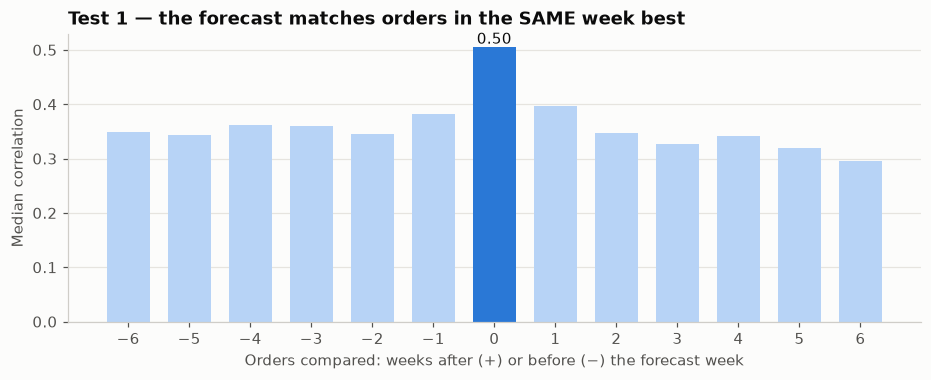

In [5]:
# Test 1: correlation between forecast in week t and orders in week t+offset, per series (median across series)
rec = panel[panel["recorded"]]
offsets = range(-6, 7)
med_corr = {}
for off in offsets:
    vals = []
    for _, g in panel.groupby("series_id"):
        g = g.set_index("week")
        pair = pd.concat([g["forecast"], g["orders"].shift(-off)], axis=1).dropna()
        if len(pair) >= 20 and pair.std().min() > 0:
            vals.append(pair.corr().iloc[0, 1])
    med_corr[off] = np.median(vals)

fig, ax = plt.subplots(figsize=(10, 3.4))
colors = [PALETTE[0] if o == 0 else "#b7d3f6" for o in offsets]
ax.bar(list(offsets), list(med_corr.values()), color=colors, width=0.7)
ax.set(title="Test 1 — the forecast matches orders in the SAME week best",
       xlabel="Orders compared: weeks after (+) or before (−) the forecast week", ylabel="Median correlation")
ax.set_xticks(list(offsets))
ax.annotate(f"{med_corr[0]:.2f}", (0, med_corr[0]), ha="center", va="bottom", color="#0b0b0b")
plt.show()

In [6]:
# Test 2: forecast / (sum of orders over the next k weeks) per series, median across series
rows = []
for k in [1, 2, 4, 13]:
    ratios = []
    for _, g in panel.groupby("series_id"):
        g = g.set_index("week")
        fut = g["orders"][::-1].rolling(k).sum()[::-1]          # orders in weeks t .. t+k-1
        pair = pd.concat([g["forecast"], fut], axis=1).dropna()
        if pair.iloc[:, 1].sum() > 0:
            ratios.append(pair.iloc[:, 0].sum() / pair.iloc[:, 1].sum())
    rows.append({"forecast compared with": f"orders summed over {k} week(s)", "median ratio": np.median(ratios)})
pd.DataFrame(rows)

,forecast compared with,median ratio
0,orders summed over 1 week(s),1.57
1,orders summed over 2 week(s),0.84
2,orders summed over 4 week(s),0.43
3,orders summed over 13 week(s),0.13


If the forecast were a 4- or 13-week total, the ratio would be near 1.0 at that length. It isn't: at 4 and 13 weeks the forecast is far *smaller* than the order total. The forecast is a **weekly** number that tends to sit **above** one week of orders.

In [7]:
# Test 3: where is the over-forecast? Ratio of total forecast to total orders (recorded weeks only)
def ratio_table(by):
    t = rec.groupby(by)[["forecast", "orders"]].sum()
    t["forecast ÷ orders"] = t["forecast"] / t["orders"]
    t["share of all orders"] = t["orders"] / t["orders"].sum()
    return t

by_dc = ratio_table("dc")
by_dc.style.format({"forecast": "{:,.0f}", "orders": "{:,.0f}", "forecast ÷ orders": "{:.2f}×",
                    "share of all orders": "{:.1%}"})

,forecast,orders,forecast ÷ orders,share of all orders
dc,,,,
ALPHA,"33,831,160","29,923,552",1.13×,9.3%
BETA,"1,589,137","1,502,405",1.06×,0.5%
DELTA,"175,072,519","70,092,309",2.50×,21.8%
EPSILON,"690,026,765","145,440,034",4.74×,45.2%
GAMMA,"118,530,946","74,889,495",1.58×,23.3%


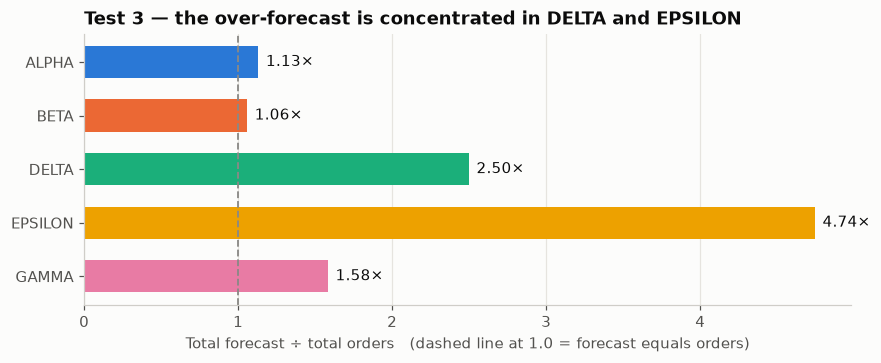

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
vals = by_dc["forecast ÷ orders"].reindex(DC_ORDER)
ax.barh(vals.index, vals.values, color=[DC_COLORS[d] for d in vals.index], height=0.6)
ax.axvline(1, color=NEUTRAL, linewidth=1.2, linestyle="--")
for y, v in enumerate(vals.values):
    ax.text(v + 0.05, y, f"{v:.2f}×", va="center", color="#0b0b0b")
ax.invert_yaxis()
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Test 3 — the over-forecast is concentrated in DELTA and EPSILON", xlabel="Total forecast ÷ total orders   (dashed line at 1.0 = forecast equals orders)")
plt.show()

### Verdict on the forecast column
**Evidence from the data:**
- It is a **same-week** forecast (Test 1 peaks at offset 0).
- It is **not** a multi-week total (Test 2).
- The over-forecast is **not uniform**. ALPHA and BETA are only slightly above 1.0, while DELTA and EPSILON forecast several times their orders (Test 3).

The headline "+217% bias" is therefore mostly a **DC-specific problem**. That's exactly the kind of finding a demand planner brings to an S&OP meeting ("our EPSILON forecast process is broken"), rather than a reason to throw the data away.

**What the sources say:**

- **Confirmed (paper abstract):** the data covers 187 consecutive weeks for *one* of Intel's five sales geographies, all five DCs in it. It records "weekly forecasted demand", "actual customer orders" and an average-selling-price category for each SKU at each location. The authors themselves report **"significant forecast bias"** and **differences in forecast error between distribution centers**. Our DC pattern matches the paper's own headline finding, so it is not a data error.
- **Not publicly confirmed:** how far ahead the forecast was made (its lag), whether missing weeks mean zero orders, the calendar dates, and which direction the price groups run. These are only in the full paper, which is behind a paywall. Until we can read it, we label them as **assumptions** (see `docs/DECISIONS_LOG.md`) and test how sensitive results are to them.
- **Unconfirmed hint:** quantities may have been **scaled by a constant** to anonymise them. Ratios, WMAPE and bias % are unaffected by scaling, but absolute unit volumes may not be Intel's real numbers. We therefore never quote volumes or dollar values as real Intel figures.

**So what for planning?**
- **Day 2** scores Intel's forecast **separately by DC**, not just in total. A single total number hides where the problem is.
- When we build our own models, we'll compare them against Intel **per DC**. Beating EPSILON's forecast is easy; beating ALPHA's is the real test.

## 3. The big picture: total demand and product generations
**Excel bridge:** a PivotTable with Week in rows, Generation in columns and Sum of Orders as values, then a stacked area chart.

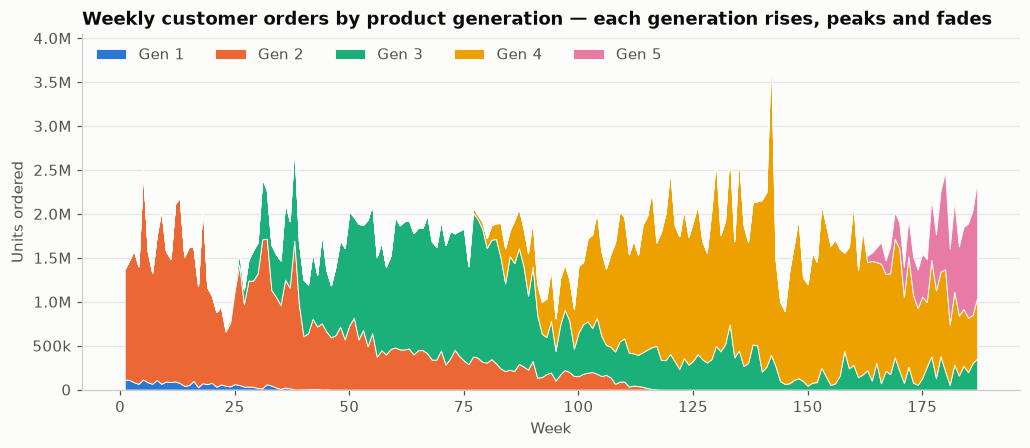

In [9]:
weekly_gen = panel.pivot_table(index="week", columns="generation", values="orders", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.stackplot(weekly_gen.index, weekly_gen.T.values, colors=[GEN_COLORS[g] for g in weekly_gen.columns],
             labels=[f"Gen {g}" for g in weekly_gen.columns], edgecolor="#fcfcfb", linewidth=0.6)
ax.set(title="Weekly customer orders by product generation — each generation rises, peaks and fades",
       xlabel="Week", ylabel="Units ordered")
thousands(ax)
ax.legend(loc="upper left", ncol=5)
plt.show()

Read the chart as **waves**: each generation launches, ramps up, peaks, then declines as the next one takes over. This is the **product life cycle** (Story 4 in the industry primer), visible in real Intel data.

**So what for planning?** A model that only "extends the recent trend" will over-forecast a generation that is about to decline, and under-forecast one that is ramping. That's why the ML models on Day 4 get **life-cycle features** (`generation`, `weeks_since_launch`).

**A trap to avoid: incomplete life cycles.** Our 187-week window cuts some life cycles off:
- SKUs **already selling in week 1** launched *before* the data starts. We never see their launch, and "weeks since launch" really means "weeks since the data started". Statisticians call this *left-censored*.
- SKUs **still selling in week 187** haven't finished their life yet (*right-censored*).

In [10]:
sku_life = panel.groupby(["sku", "generation"]).agg(first_week=("week", "min"), last_week=("week", "max")).reset_index()
sku_life["launched before data (week 1)"] = sku_life["first_week"] <= 1
sku_life["still selling at week 187"] = sku_life["last_week"] >= 187
sku_life.groupby("generation")[["launched before data (week 1)", "still selling at week 187"]].sum() \
    .assign(SKUs=sku_life.groupby("generation").size())

,launched before data (week 1),still selling at week 187,SKUs
generation,,,
1,9,0,9
2,16,0,16
3,0,6,17
4,0,21,22
5,0,22,22


Gen 1–2 were already on the market, and most of Gen 4–5 are still selling, so **Gen 3 is the only generation whose full life cycle we can see**. For the typical life-cycle shape, we therefore use only SKUs that **launched inside the window** (Gen 3–5).

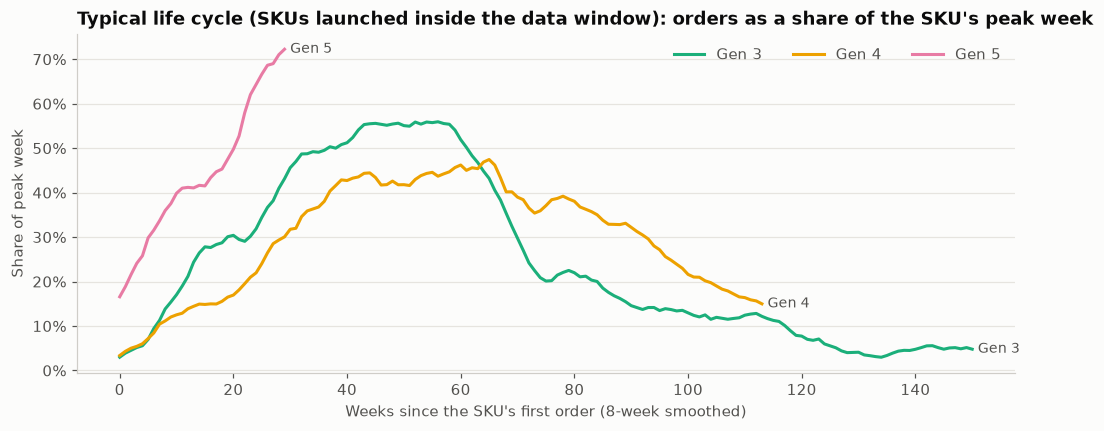

In [11]:
# Typical life-cycle shape: weekly orders per SKU (all DCs) as a share of its peak week, by weeks since launch
launched_in_window = sku_life.loc[~sku_life["launched before data (week 1)"], "sku"]
sku_week = (panel[panel["sku"].isin(launched_in_window)]
            .groupby(["sku", "generation", "weeks_since_launch"])["orders"].sum().reset_index())
sku_week["share_of_peak"] = sku_week["orders"] / sku_week.groupby("sku")["orders"].transform("max")
curve = (sku_week.groupby(["generation", "weeks_since_launch"])["share_of_peak"].mean()
         .groupby(level=0).transform(lambda s: s.rolling(8, min_periods=1, center=True).mean()).unstack(0))

fig, ax = plt.subplots(figsize=(11, 4))
for g in curve.columns:
    s = curve[g].dropna()
    s = s[s.index <= 150]
    ax.plot(s.index, s.values, color=GEN_COLORS[g], label=f"Gen {g}")
    ax.text(s.index[-1] + 1, s.values[-1], f"Gen {g}", color="#52514e", fontsize=9, va="center")
ax.set(title="Typical life cycle (SKUs launched inside the data window): orders as a share of the SKU's peak week",
       xlabel="Weeks since the SKU's first order (8-week smoothed)", ylabel="Share of peak week")
percent(ax)
ax.legend(loc="upper right", ncol=3)
plt.show()

**Reading it:** Gen 3 shows the full shape. It ramps for roughly a year, plateaus, then declines over the following year. Gen 4 follows a similar ramp, and Gen 5's curve stops early because the data ends while it is still ramping.

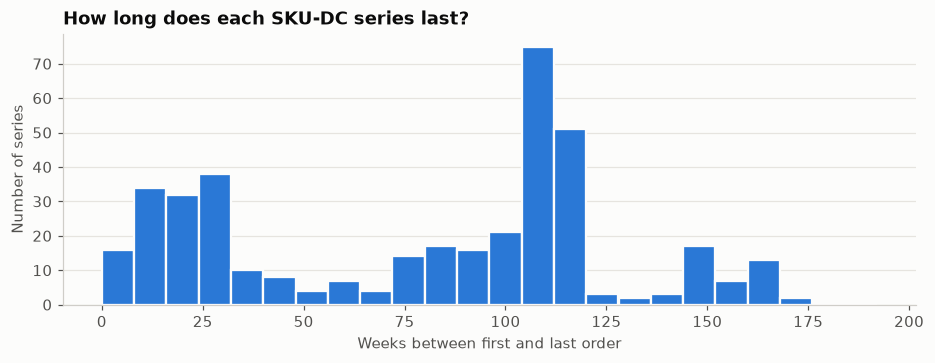

count   394.00
mean     78.00
std      48.00
min       1.00
10%      13.00
25%      26.00
50%      93.00
75%     111.00
90%     141.00
max     168.00


In [12]:
summary = series_summary(panel)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(summary["n_weeks"], bins=range(0, 195, 8), color=PALETTE[0], edgecolor="#fcfcfb", linewidth=1.5)
ax.set(title="How long does each SKU-DC series last?", xlabel="Weeks between first and last order",
       ylabel="Number of series")
plt.show()
print(summary["n_weeks"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

**So what for planning?** Many series are **short**, a few months to a year and a half. Classic per-series statistical models (ARIMA, ETS) need a decent history, so short series are a problem for them. **Global ML models** that learn from all series at once (Day 4) are built for this situation: a new SKU can borrow patterns from older generations.

## 4. How forecastable is each series? Demand classification
Planners classify items before choosing a method. The standard is the **Syntetos-Boylan-Croston (SBC)** scheme, using two numbers per series:
- **ADI** (average demand interval): on average, how many weeks between non-zero orders? 1.0 = orders every week.
- **CV²** (squared coefficient of variation of order *sizes*): how much the size of an order varies.

| | Stable sizes (CV² < 0.49) | Volatile sizes (CV² ≥ 0.49) |
|---|---|---|
| **Regular timing (ADI < 1.32)** | **Smooth**: ETS/ARIMA work well | **Erratic**: hard; bigger buffers, ML |
| **Many zero weeks (ADI ≥ 1.32)** | **Intermittent**: Croston/TSB | **Lumpy**: hardest of all |

In [13]:
classes = ["smooth", "erratic", "intermittent", "lumpy"]
cls = summary[summary["demand_class"].isin(classes)]
cls_table = cls.groupby("demand_class").agg(series=("sku", "size"), total_orders=("total_orders", "sum")).reindex(classes)
cls_table["share of series"] = cls_table["series"] / cls_table["series"].sum()
cls_table["share of volume"] = cls_table["total_orders"] / cls_table["total_orders"].sum()
print(f"Series with too few non-zero weeks to classify: {(summary['demand_class'] == 'insufficient').sum()}")
cls_table.style.format({"total_orders": "{:,.0f}", "share of series": "{:.0%}", "share of volume": "{:.0%}"})

Series with too few non-zero weeks to classify: 6


,series,total_orders,share of series,share of volume
demand_class,,,,
smooth,53,"66,692,918",14%,21%
erratic,224,"248,018,391",58%,77%
intermittent,24,"135,740",6%,0%
lumpy,87,"6,999,075",22%,2%


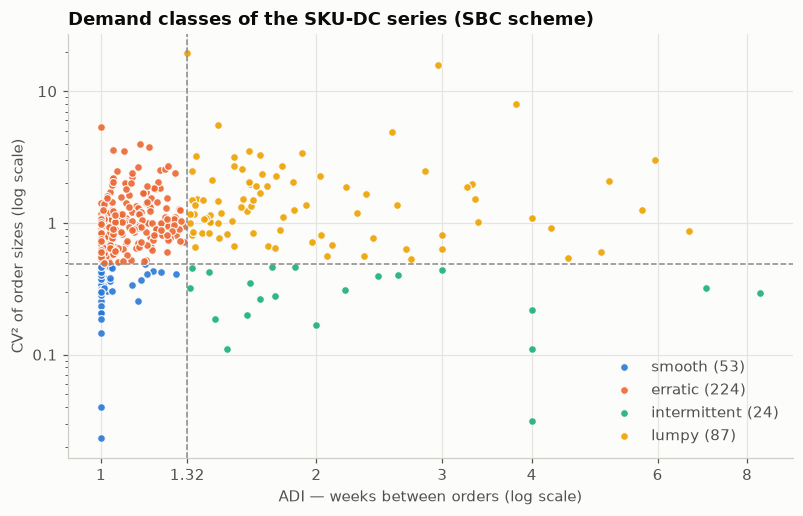

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for i, c in enumerate(classes):
    d = cls[cls["demand_class"] == c]
    ax.scatter(d["adi"], d["cv2_nonzero"], s=26, color=PALETTE[i], label=f"{c} ({len(d)})",
               edgecolor="#fcfcfb", linewidth=0.8, alpha=0.9)
ax.axvline(1.32, color=NEUTRAL, linestyle="--", linewidth=1)
ax.axhline(0.49, color=NEUTRAL, linestyle="--", linewidth=1)
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(FixedLocator([1, 1.32, 2, 3, 4, 6, 8]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
ax.set(title="Demand classes of the SKU-DC series (SBC scheme)",
       xlabel="ADI — weeks between orders (log scale)", ylabel="CV² of order sizes (log scale)")
ax.grid(axis="x")
ax.legend(loc="lower right")
plt.show()

**So what for planning?**
- Most Intel series are **erratic**: orders arrive almost every week, but their size jumps around a lot. That's typical of semiconductors, where big OEM customers place large, uneven orders. Erratic series carry most of the **volume** too (see the table).
- Lumpy and intermittent series are numerous but small in volume. They matter for service level, much less for total inventory value.
- There is **no single best method**. We'll compare models **by demand class** (Day 4): e.g. boosting for erratic, Croston/TSB for intermittent and lumpy.
- Erratic, high-value items need the most safety stock and planner attention. The **XYZ** part of ABC-XYZ on Day 5 builds on this.

## 5. How do the distribution centers differ?
**Excel bridge:** one PivotTable with DC in rows and several value fields.

In [15]:
dc_profile = summary.groupby("dc").agg(
    series=("sku", "size"), skus=("sku", "nunique"), total_orders=("total_orders", "sum"),
    median_series_cv=("cv", "median"), zero_week_share=("zero_share", "mean"))
dc_profile["share of volume"] = dc_profile["total_orders"] / dc_profile["total_orders"].sum()
dc_profile["forecast ÷ orders"] = by_dc["forecast ÷ orders"]
dc_profile = dc_profile.reindex(DC_ORDER)
dc_profile.style.format({"total_orders": "{:,.0f}", "median_series_cv": "{:.2f}", "zero_week_share": "{:.0%}",
                         "share of volume": "{:.0%}", "forecast ÷ orders": "{:.2f}×"})

,series,skus,total_orders,median_series_cv,zero_week_share,share of volume,forecast ÷ orders
dc,,,,,,,
ALPHA,80,80,"29,923,552",1.28,25%,9%,1.13×
BETA,60,60,"1,502,405",1.40,38%,0%,1.06×
DELTA,84,84,"70,092,309",0.94,10%,22%,2.50×
EPSILON,84,84,"145,440,034",0.90,9%,45%,4.74×
GAMMA,86,86,"74,889,495",1.16,15%,23%,1.58×


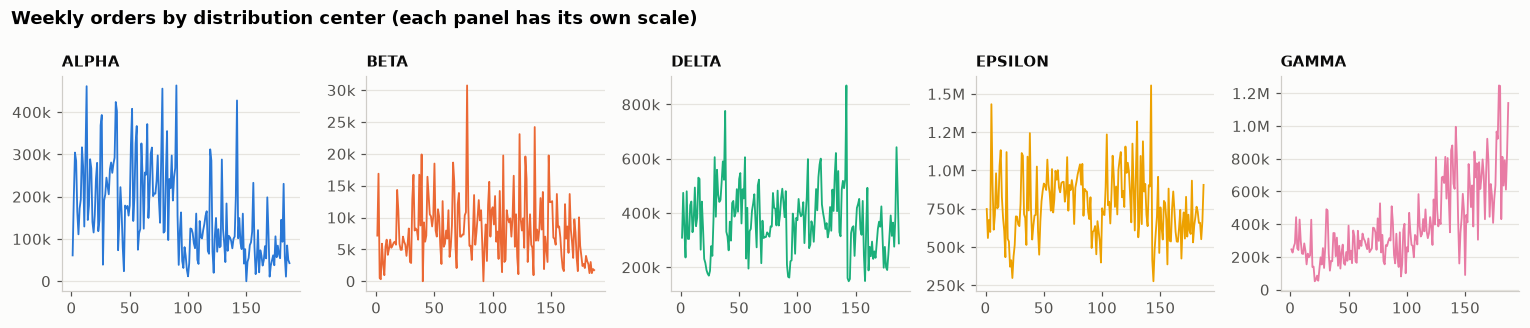

In [16]:
weekly_dc = panel.pivot_table(index="week", columns="dc", values="orders", aggfunc="sum").fillna(0)[DC_ORDER]
fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharex=True)
for ax, dc in zip(axes, DC_ORDER):
    ax.plot(weekly_dc.index, weekly_dc[dc], color=DC_COLORS[dc], linewidth=1.2)
    ax.set_title(dc, fontsize=10)
    thousands(ax)
fig.suptitle("Weekly orders by distribution center (each panel has its own scale)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()

**So what for planning?** The DCs differ in size, in volatility and in how well Intel forecasts them. Inventory policy and forecast review should be **DC-specific**: one global safety-stock rule would over-stock some DCs and under-stock others.

## 6. Is there a quarter-end pattern?
Many semiconductor customers order heavily at **quarter end** to hit targets ("hockey stick"). A quarter is 13 weeks. We don't know which calendar week week 1 was, so we can only check whether a **13-week rhythm** exists, not which week is quarter end.

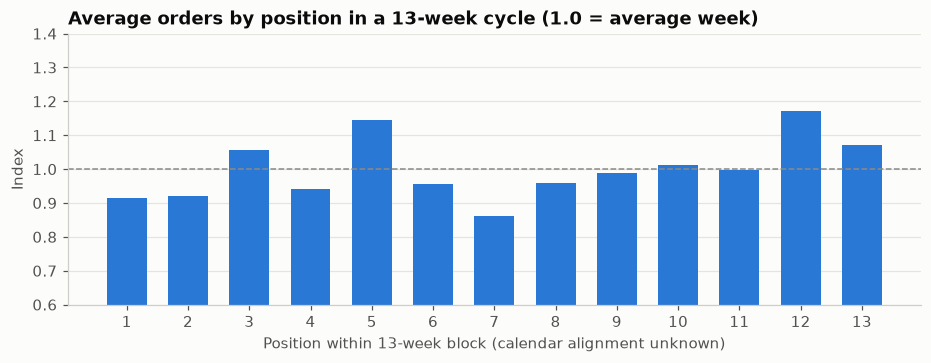

Highest positions: {12: 1.17, 5: 1.15, 13: 1.07}


In [17]:
panel["pos_in_13wk"] = (panel["week"] - 1) % 13 + 1
idx = panel.groupby("pos_in_13wk")["orders"].mean()
idx = idx / idx.mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(idx.index, idx.values, color=PALETTE[0], width=0.65)
ax.axhline(1, color=NEUTRAL, linestyle="--", linewidth=1)
ax.set(title="Average orders by position in a 13-week cycle (1.0 = average week)",
       xlabel="Position within 13-week block (calendar alignment unknown)", ylabel="Index")
ax.set_xticks(range(1, 14))
ax.set_ylim(0.6, 1.4)
plt.show()
print("Highest positions:", idx.sort_values(ascending=False).head(3).round(2).to_dict())

**So what for planning?** Check the chart: if a few positions stand clearly above 1.0 and repeat, there is a quarterly rhythm worth giving the models (a "position in quarter" feature, or seasonality of 13 weeks in ETS). If the bars hover around 1.0, quarter effects are weak. Day 3 tests seasonal vs. non-seasonal models properly instead of assuming.

## 7. Order spikes: real demand or "pull-forward"?
From Story 2 (the bullwhip): customers sometimes order far more than they need in one week, then order less afterwards. We flag a **spike** when a week's orders exceed **3× the median of the previous 8 weeks** (using only past weeks, with no peeking), then look at what happens in the 4 weeks after.

In [18]:
sp = panel.sort_values(["series_id", "week"]).copy()
by_series = sp.groupby("series_id")["orders"]
sp["baseline"] = by_series.transform(lambda s: s.shift(1).rolling(8, min_periods=6).median())   # past 8 weeks only
sp["next4"] = by_series.transform(lambda s: s[::-1].shift(1).rolling(4).mean()[::-1])          # weeks t+1..t+4
sp["spike"] = (sp["orders"] > 3 * sp["baseline"]) & (sp["baseline"] > 0)
sp["stage"] = np.where(sp["series_age"] < 26, "early life (first 26 weeks)", "mature (26+ weeks)")
spikes = sp[sp["spike"]].dropna(subset=["next4"])

print(f"Spike weeks: {sp['spike'].sum():,} of {sp['baseline'].notna().sum():,} weeks with a baseline "
      f"({sp['spike'].sum() / sp['baseline'].notna().sum():.1%}); "
      f"they hold {sp.loc[sp['spike'], 'orders'].sum() / panel['orders'].sum():.1%} of all units ordered")

after = spikes.groupby("stage").apply(lambda d: pd.Series({
    "spikes": len(d),
    "next 4 wks ÷ pre-spike baseline (median)": (d["next4"] / d["baseline"]).median(),
    "next 4 wks ÷ spike week (median)": (d["next4"] / d["orders"]).median(),
    "share followed by below-baseline weeks": (d["next4"] < d["baseline"]).mean(),
}), include_groups=False)
after.style.format({"spikes": "{:,.0f}", "next 4 wks ÷ pre-spike baseline (median)": "{:.2f}×",
                    "next 4 wks ÷ spike week (median)": "{:.0%}", "share followed by below-baseline weeks": "{:.0%}"})

Spike weeks: 2,618 of 28,518 weeks with a baseline (9.2%); they hold 11.4% of all units ordered


,spikes,next 4 wks ÷ pre-spike baseline (median),next 4 wks ÷ spike week (median),share followed by below-baseline weeks
stage,,,,
early life (first 26 weeks),952,3.31×,63%,11%
mature (26+ weeks),"1,542",1.85×,37%,24%


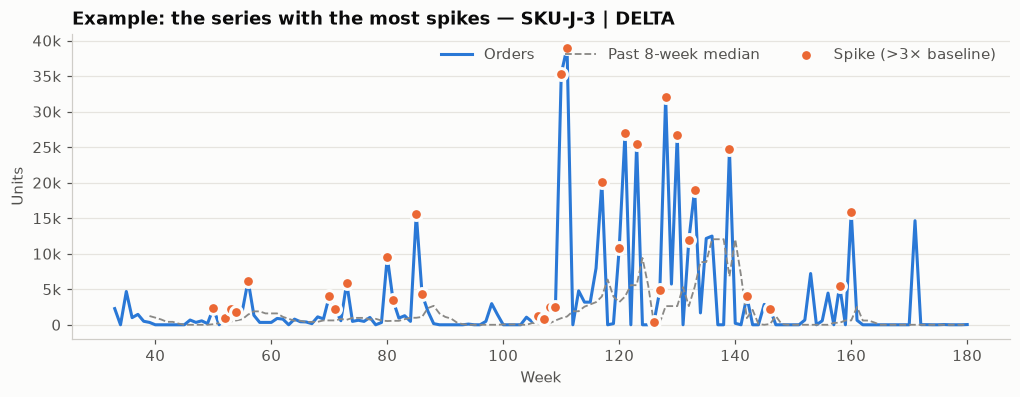

In [19]:
example = sp[sp["series_id"] == spikes.groupby("series_id").size().idxmax()]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(example["week"], example["orders"], color=PALETTE[0], label="Orders")
ax.plot(example["week"], example["baseline"], color=NEUTRAL, linewidth=1.2, linestyle="--", label="Past 8-week median")
s = example[example["spike"]]
ax.scatter(s["week"], s["orders"], s=60, color=PALETTE[1], edgecolor="#fcfcfb", linewidth=2, zorder=3, label="Spike (>3× baseline)")
ax.set(title=f"Example: the series with the most spikes — {example['series_id'].iloc[0]}", xlabel="Week", ylabel="Units")
thousands(ax)
ax.legend(loc="upper right", ncol=3)
plt.show()

**Reading the table**
- **Early life:** after a spike, orders stay well *above* the old baseline. The spike was the start of the **ramp**, which is real new demand.
- **Mature products:** after a spike, orders fall back to a fraction of the spike week, and some spikes are followed by weeks *below* the old baseline. Those spikes were largely **one-off or pulled-forward orders**, the bullwhip behaviour from Story 2.

**So what for planning?**
- Treat a spike differently depending on **life stage**. For a ramping product it's a signal to raise the forecast. For a mature product, don't let one big week inflate the next forecast.
- Spikes are a major source of forecast error. Use **robust** measures (medians) for baselines, and give models a life-stage feature (`series_age`, `weeks_since_launch`), so they can learn the difference.

## 8. Market context: U.S. electronics orders and semiconductor production (FRED)

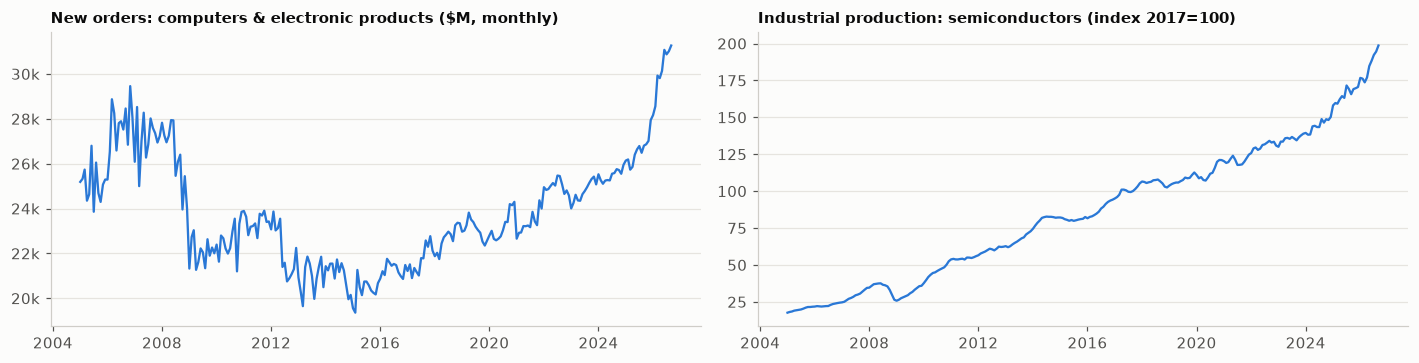

In [20]:
fred = {sid: load_fred(sid) for sid in ["A34SNO", "IPG3344S"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
titles = {"A34SNO": "New orders: computers & electronic products ($M, monthly)",
          "IPG3344S": "Industrial production: semiconductors (index 2017=100)"}
for ax, (sid, s) in zip(axes, fred.items()):
    s = s[s.index >= "2005-01-01"]
    ax.plot(s.index, s.values, color=PALETTE[0], linewidth=1.5)
    ax.set_title(titles[sid], fontsize=10)
    thousands(ax)
fig.tight_layout()
plt.show()

**Can we use FRED as a model input?** Only if we know which calendar weeks the Intel data covers. The dataset gives relative weeks (1–187) and no dates (see Section 2's source note), so lining the two up would be guesswork. **Guesswork features are a form of leakage risk**: the model could learn a fake relationship.

**Decision:** FRED is used as **market context** in the dashboard and story, not as a model feature. *(Logged in `docs/DECISIONS_LOG.md`.)* This is an honest limitation to mention in interviews, and planners face it all the time when internal and external data don't share a calendar.

## 9. Save the clean data for the next days

In [21]:
panel_saved = build_processed(save=True)          # same cleaning, saved to data/processed/
summary.to_csv(Path.cwd().parent / "data" / "processed" / "series_summary.csv")
print(f"Saved weekly panel: {len(panel_saved):,} rows, and series summary: {len(summary)} series")

Saved weekly panel: 30,835 rows, and series summary: 394 series


---
## What a demand planner takes away
1. **Understand the extract before trusting it.** Rows existed only for weeks with orders. Treating missing as "no data" instead of "zero demand" would have overstated demand.
2. **A shocking KPI is a question, not a conclusion.** The +217% bias turned out to be a same-week forecast that is badly over-forecast in **two DCs**, and only mildly biased in the others.
3. **Semiconductor demand is erratic and life-cycle driven.** Most series are erratic, many are short, and generations come in waves. Method choice and inventory policy must reflect that.
4. **Segment everything:** by DC, by demand class, by generation. Averages hide where the problems are.
5. **Be honest about data limits.** Without calendar dates, FRED is context, not a feature.

## Checkpoint questions
1. Why do we believe a missing week means *zero orders* rather than *no data*? What would go wrong if we ignored the gaps?
2. Which two pieces of evidence show that `Forecasted Demand` is a single-week forecast?
3. The total bias is about +217%, but ALPHA's forecast-to-orders ratio is close to 1. What does that tell you about how you should report forecast accuracy in an S&OP meeting?
4. Most series are "erratic" in the SBC scheme. What does that mean, and how could it affect safety stock?
5. Why did we decide **not** to use FRED data as a model feature?